We first import the necessary modules and classes and load the data using ```pd.read_csv(...)```. We also do some data-preprocessing where we reset the index, sort the DataFrame according to the battery ID and cycle index and where we transform the battery ID column such that it is easier to work with.
We also collect the different chemistry types, climate zones and degradation statuses, and we define the train-validation split.

In [48]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
import numpy as np
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    silhouette_score
)

g = lambda x: int(x.split('-')[-1])

df = pd.read_csv("battery_observations.csv", index_col=0)
meta = pd.read_csv("battery_metadata.csv", index_col=0)
train_labels = pd.read_csv("train_batteries.csv")["battery_id"].apply(g)
val_labels = pd.read_csv("validation_batteries.csv")["battery_id"].apply(g)

df2 = df.join(meta[["climate_zone", "chemistry"]])
df2 = df2.sort_values(["battery_id", "cycle_index"])
df2 = df2.reset_index()
meta = meta.reset_index()

df2["battery_id"] = df2["battery_id"].apply(g)
meta["battery_id"] = meta["battery_id"].apply(g)
battery_ids = list(set(df2["battery_id"]))
materials = list(set(meta["chemistry"]))
climate_zones = list(set(meta["climate_zone"]))
labels = list(set(df2["degradation_status"]))

train = df2[df2["battery_id"].isin(train_labels)]
val = df2[df2["battery_id"].isin(val_labels)]

In [53]:
cycle_features = [
    "depth_of_discharge_pct",
    "high_soc_exposure_fraction",
    "low_soc_exposure_fraction",
    "charge_c_rate",
    "discharge_c_rate",
    "charge_current_a",
    "discharge_current_a",
    "charge_duration_min",
    "discharge_duration_min",
    "energy_discharged_kwh",
    "ambient_temp_c",
    #"pack_temp_c",
    "cooling_active",
]

extended_features = cycle_features + [
    "battery_age_days",
    "time_since_previous_cycle_hours",
    "equivalent_full_cycles",
    "cumulative_high_temp_hours",
    "pack_voltage_charge_v",
    "pack_voltage_discharge_v"
]


minimal_features = [
    "depth_of_discharge_pct",
    "equivalent_full_cycles",
    "battery_age_days",
    "energy_discharged_kwh"
]



We should also inspect each variable we wish to use for the K-means algorithm on containing nan-values. If any selected variable holds any nan-values, we should drop it or possibly fill these in with a standardised value.

In [36]:
import pandas as pd
import numpy as np

X_train_raw = train[extended_features]
X_val_raw = val[extended_features]

# total nans per feature
print("Train NaNs per column:")
print(X_train_raw.isna().sum().sort_values(ascending=False))

print("Validation NaNs per column:")
print(X_val_raw.isna().sum().sort_values(ascending=False))

# total counts
print("Train rows with any NaN:", X_train_raw.isna().any(axis=1).sum())
print("Train total NaN cells:", X_train_raw.isna().sum().sum())

print("Validation rows with any NaN:", X_val_raw.isna().any(axis=1).sum())
print("Validation total NaN cells:", X_val_raw.isna().sum().sum())

train_nan_rows = X_train_raw[X_train_raw.isna().any(axis=1)]
val_nan_rows = X_val_raw[X_val_raw.isna().any(axis=1)]

print("Train rows containing NaNs:")
print(train_nan_rows.head(20))

print("Validation rows containing NaNs:")
print(val_nan_rows.head(20))

Train NaNs per column:
pack_temp_c                        1242
high_soc_exposure_fraction            0
depth_of_discharge_pct                0
low_soc_exposure_fraction             0
charge_c_rate                         0
charge_current_a                      0
discharge_c_rate                      0
charge_duration_min                   0
discharge_duration_min                0
energy_discharged_kwh                 0
discharge_current_a                   0
ambient_temp_c                        0
cooling_active                        0
battery_age_days                      0
time_since_previous_cycle_hours       0
equivalent_full_cycles                0
cumulative_high_temp_hours            0
pack_voltage_charge_v                 0
pack_voltage_discharge_v              0
dtype: int64
Validation NaNs per column:
pack_temp_c                        229
high_soc_exposure_fraction           0
depth_of_discharge_pct               0
low_soc_exposure_fraction            0
charge_c_rate       

We exclude ```pack_temp``` here because it contains NaN-values.

In [37]:
cycle_features = [x for x in cycle_features if x != "pack_temp_c"]
extended_features = [x for x in extended_features if x != "pack_temp_c"]

In [44]:
preprocess = Pipeline([
    ("scaler", StandardScaler()),
    ("variance", VarianceThreshold(threshold=0.0))
])
X_train_transformed = preprocess.fit_transform(train[minimal_features])
X_val_transformed = preprocess.transform(val[minimal_features])

# K-means
kmeans = KMeans(n_clusters=4, n_init=25, random_state=42)
train_clusters = kmeans.fit_predict(X_train_transformed)
val_clusters = kmeans.predict(X_val_transformed)

print(train_clusters)
print()
print(val_clusters)

train_clusters_df = train.copy()
val_clusters_df = val.copy()

train_clusters_df["kmeans_cluster"] = train_clusters
val_clusters_df["kmeans_cluster"] = val_clusters

[2 0 0 ... 3 3 1]

[2 2 2 ... 2 2 2]


In [50]:




# --------------------------------------------------
# 1. Preprocess: scale and remove zero-variance columns
# --------------------------------------------------

no_pca_preprocess = Pipeline([
    ("scaler", StandardScaler()),
    ("variance", VarianceThreshold(threshold=0.0))
])

X_train_no_pca = no_pca_preprocess.fit_transform(train[minimal_features])
X_val_no_pca = no_pca_preprocess.transform(val[minimal_features])

y_train = train["degradation_status"].to_numpy()
y_val = val["degradation_status"].to_numpy()

class_names = ["Normal", "Moderate", "Severe", "Critical"]


# --------------------------------------------------
# 2. Fit K-means directly on all features
# --------------------------------------------------

n_clusters = 4

kmeans_no_pca = KMeans(
    n_clusters=n_clusters,
    n_init=25,
    random_state=42
)

train_clusters_no_pca = kmeans_no_pca.fit_predict(X_train_no_pca)
val_clusters_no_pca = kmeans_no_pca.predict(X_val_no_pca)


# --------------------------------------------------
# 3. Map clusters to degradation status
#    using training labels only
# --------------------------------------------------

mapping_df = pd.DataFrame({
    "cluster": train_clusters_no_pca,
    "degradation_status": y_train
})

cluster_to_status_no_pca = (
    mapping_df
    .groupby("cluster")["degradation_status"]
    .agg(lambda s: s.mode().iloc[0])
    .to_dict()
)

print("Cluster-to-status mapping:")
print(cluster_to_status_no_pca)

val_predictions_no_pca = np.array([
    cluster_to_status_no_pca[cluster]
    for cluster in val_clusters_no_pca
])


# --------------------------------------------------
# 4. Evaluate clustering and mapped classification
# --------------------------------------------------

ari_no_pca = adjusted_rand_score(
    y_val,
    val_clusters_no_pca
)

nmi_no_pca = normalized_mutual_info_score(
    y_val,
    val_clusters_no_pca
)

accuracy_no_pca = accuracy_score(
    y_val,
    val_predictions_no_pca
)

macro_f1_no_pca = f1_score(
    y_val,
    val_predictions_no_pca,
    labels=class_names,
    average="macro",
    zero_division=0
)

# Silhouette is computationally expensive on very large data.
# Use a random sample if needed.
sample_idx = np.random.RandomState(42).choice(
    X_train_no_pca.shape[0],
    size=min(10_000, X_train_no_pca.shape[0]),
    replace=False
)

silhouette_no_pca = silhouette_score(
    X_train_no_pca[sample_idx],
    train_clusters_no_pca[sample_idx]
)

print("\nNo-PCA K-means results")
print(f"ARI: {ari_no_pca:.4f}")
print(f"NMI: {nmi_no_pca:.4f}")
print(f"Silhouette: {silhouette_no_pca:.4f}")
print(f"Accuracy: {accuracy_no_pca:.4f}")
print(f"Macro F1: {macro_f1_no_pca:.4f}")
print(f"Predicted classes: {np.unique(val_predictions_no_pca)}")


# --------------------------------------------------
# 5. Detailed validation report
# --------------------------------------------------

print("\nValidation classification report:")
print(classification_report(
    y_val,
    val_predictions_no_pca,
    labels=class_names,
    zero_division=0
))

confusion_no_pca = pd.DataFrame(
    confusion_matrix(
        y_val,
        val_predictions_no_pca,
        labels=class_names
    ),
    index=[f"Actual {label}" for label in class_names],
    columns=[f"Predicted {label}" for label in class_names]
)

print("\nValidation confusion matrix:")
print(confusion_no_pca)


# --------------------------------------------------
# 6. Inspect cluster profiles
# --------------------------------------------------

train_no_pca_df = train.copy()
val_no_pca_df = val.copy()

train_no_pca_df["kmeans_cluster"] = train_clusters_no_pca
val_no_pca_df["kmeans_cluster"] = val_clusters_no_pca

train_no_pca_df["predicted_degradation_status"] = [
    cluster_to_status_no_pca[c]
    for c in train_clusters_no_pca
]

val_no_pca_df["predicted_degradation_status"] = val_predictions_no_pca

print("\nCluster profiles:")
print(
    train_no_pca_df
    .groupby("kmeans_cluster")[minimal_features]
    .mean()
    .round(3)
)

print("\nCluster-status distribution (training):")
print(
    pd.crosstab(
        train_no_pca_df["kmeans_cluster"],
        train_no_pca_df["degradation_status"],
        normalize="index"
    ).round(3)
)

print("\nCluster-status distribution (validation):")
print(
    pd.crosstab(
        val_no_pca_df["kmeans_cluster"],
        val_no_pca_df["degradation_status"],
        normalize="index"
    ).round(3)
)

Cluster-to-status mapping:
{0: 'Normal', 1: 'Severe', 2: 'Normal', 3: 'Severe'}

No-PCA K-means results
ARI: 0.1561
NMI: 0.2060
Silhouette: 0.3453
Accuracy: 0.5834
Macro F1: 0.3531
Predicted classes: ['Normal' 'Severe']

Validation classification report:
              precision    recall  f1-score   support

      Normal       0.54      0.99      0.70      8638
    Moderate       0.00      0.00      0.00      8547
      Severe       0.67      0.77      0.72      7774
    Critical       0.00      0.00      0.00        27

    accuracy                           0.58     24986
   macro avg       0.30      0.44      0.35     24986
weighted avg       0.39      0.58      0.46     24986


Validation confusion matrix:
                 Predicted Normal  Predicted Moderate  Predicted Severe  \
Actual Normal                8567                   0                71   
Actual Moderate              5656                   0              2891   
Actual Severe                1764                   0  

# Validation of K-means

In order to validate this unsupervised ML model, we have to perform measures of the accuracy of the clusters.

### Validating K-Means

```pd.crosstab``` compares two instances of categorical variables in where they appear within a dataset. Here, we can use it for the variables ```degradation_status``` (a string) and ```kmeans_cluster``` (an integer between 0 and 3). We use this method to see where the samples across degradation status are distributed among the clusters generated from K-means.

### Rand Index (RI)
This is a statistic to measure the similarity between two clusterings. Its formula is
$RI=(TP+TN)/(TP+TN+FP+FN)$
where $TP,TN,FP,FN$ are the true positives, true negatives, false positives and false negatives, respectively.
It is computed by looking at all the possible $\binom{n}{2}$ pairs in the dataset and comparing the true label with the clustered (predicted) label.

### ARI (Adjusted Rand Score)
This is a statistic to measure the quality of data clustering. It measures the accuracy of the predicted values with respect to the ground-truth values. It is a normalized version of the Rand Index and is less sensible to noise and chance. Its formula is
$ARI = (RI - E[RI]) / (\text{max}(RI)-E[RI])$

##### What are max(RI) and E[RI] and how are they calculated?

We first make a contingency table, ie. a square matrix where position $(i,j)$ corresponds with the number of items in the dataset that are both in the ground-truth cluster $i$ and in the predicted cluster $j$. Next we define $a_i$ to be the sum of row $i$, ie. the total number of items in ground-truth cluster $i$, and $b_j$ to be the sum of column $j$, ie. the total number of items in the predicted cluster $j$. we can then calculate $\text{max}(RI)$ and $E[RI]$:

$\text{max}(RI)=\frac{1}{2}(\sum_i\binom{a_i}{2}+\sum_j\binom{b_j}{2})$

$E[RI]=\binom{n}{2}^{-1}(\sum_i\binom{a_i}{2}+\sum_j\binom{b_j}{2})$

$E[RI]$ represents the score one would get if one randomly shuffled the cluster labels around while keeping the cluster sizes the same, while $\text{max}(RI)$ is the average of the internal pairs in both groupings, which represents the maximum possible value of the agreement between ground-truth and predicted labeling.

### NMI (Normalized Mutual Information)

This is another accuracy measure, but unlike ARI it doesn't count pairings, but rather uses Shannon-entropy and represents the amount of information one cluster shares with another. It quantifies the reduction in uncertainty about the true cluster labels given knowledge of the predicted cluster labels.

$NMI(U,V)=\text{MI}(U,V)/\text{Normalizer}(H(U),H(V))$

where $H(U),H(V)$ are the entropies of the datasets $U$ and $V$ respectively.

##### What are MI(U,V) and Normalizer(H(U),H(V))?

$\text{MI}(U,V) is the Mutual Information between $U$ and $V$ and is calculated as

$\text{MI}(U,V)=\sum_i\sum_j P(i,j)\text{log}(\frac{P(i,j)}{P(i)P(j)})$

This determines how much knowing clustering $V$ reduces our uncertainty about clustering $U$. one can see that if $U$ and $V$ are completely independent, then $P(i,j)=P(i)P(j)$ and $\text{MI}(U,V)=0$. If $U=V$ then $\text{MI}(U,V)$ equals the total entropy of the common dataset. Here, $P(i)$ is the probability of a random point landing in cluster $i$ and $P(i,j)$ is the probability of a random point landing in true cluster $i$ and predicted cluster $j$.

$\text{Normalizer}(H(U),H(V))$ is a normalizer for the NMI quantity. We use this because the mutual information is uncapped, and we wish to normalize this to ensure the NMI is between 0 and 1. It is usually calculated as $\text{Normalizer}(H(U),H(V))=\sqrt{H(U)\cdot H(V)}$.

### Accuracy

This is simply calculated as $\frac{\text{number of correct predictions}}{\text{total number of predictions}}$. It is a simple measure and can be misleading when the sizes of the clusters are not balanced.

### Macro F1

This calculates $\frac{1}{n}\sum_{i=1}^n\text{F1}_{\text{class}\ i}$, where $\text{F1}_{\text{class}\ i}=2\cdot\frac{\text{precision}_i\cdot\text{recall}_i}{\text{precision}_i+\text{recall}_i}$, with $\text{recall}_i=\frac{TP_i}{TP_i+FN_i}$ and $\text{precision}_i=\frac{TP_i}{TP_i+FP_i}$.

 n_components  explained_variance      ari      nmi  accuracy  macro_f1  n_predicted_classes
            2            0.408592 0.007526 0.010616  0.378092  0.280241                    3
           10            0.945783 0.061429 0.079313  0.464340  0.279770                    2
            9            0.918572 0.061174 0.079384  0.464260  0.279721                    2
            7            0.838207 0.059934 0.079816  0.463740  0.279389                    2
           11            0.971006 0.060503 0.078663  0.463580  0.279295                    2
           12            0.983420 0.060763 0.078310  0.463460  0.279238                    2
           13            0.990718 0.060718 0.078162  0.463420  0.279209                    2
            6            0.784914 0.059547 0.079887  0.463259  0.279085                    2
           14            0.996433 0.060357 0.078427  0.463179  0.279050                    2
           18            1.000000 0.060415 0.077935  0.463139  0.27903

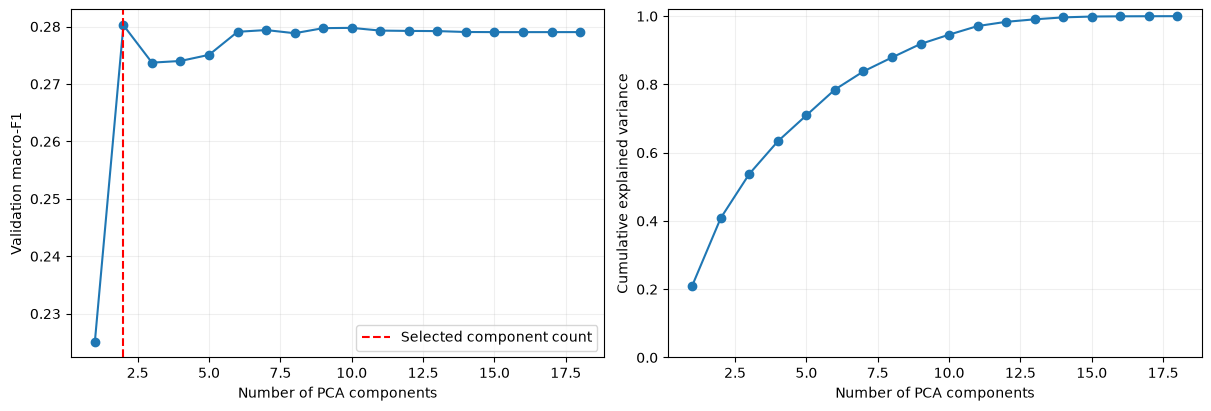

In [ ]:
# --------------------------------------------------
# 1. Fit preprocessing BEFORE PCA on training data
# --------------------------------------------------

base_preprocess = Pipeline([
    ("scaler", StandardScaler()),
    ("variance", VarianceThreshold(threshold=0.0)),
])

X_train_prepared = base_preprocess.fit_transform(
    train[extended_features]
)

X_val_prepared = base_preprocess.transform(
    val[extended_features]
)

y_train = train["degradation_status"].to_numpy()
y_val = val["degradation_status"].to_numpy()

class_names = ["Normal", "Moderate", "Severe", "Critical"]


# --------------------------------------------------
# 2. Choose PCA component counts to evaluate
# --------------------------------------------------

max_components = min(X_train_prepared.shape)

# Exhaustive search over all valid component counts.
component_candidates = range(1, max_components + 1)

# --------------------------------------------------
# 3. Evaluate PCA + four-cluster K-means
# --------------------------------------------------

results = []
best_model = None
best_macro_f1 = -np.inf

for n_components in component_candidates:

    pca = PCA(
        n_components=n_components,
        svd_solver="full",
        whiten=False,
        random_state=42,
    )

    X_train_pca = pca.fit_transform(X_train_prepared)
    X_val_pca = pca.transform(X_val_prepared)

    kmeans = KMeans(
        n_clusters=4,
        n_init=25,
        random_state=42,
    )

    train_clusters = kmeans.fit_predict(X_train_pca)
    val_clusters = kmeans.predict(X_val_pca)

    # Map each cluster to its most common TRAINING status.
    mapping_df = pd.DataFrame({
        "cluster": train_clusters,
        "degradation_status": y_train,
    })

    mapping = (
        mapping_df.groupby("cluster")["degradation_status"]
        .agg(lambda s: s.mode().iloc[0])
        .to_dict()
    )

    y_pred = np.array([
        mapping[cluster] for cluster in val_clusters
    ])

    macro_f1 = f1_score(
        y_val,
        y_pred,
        labels=class_names,
        average="macro",
        zero_division=0,
    )

    results.append({
        "n_components": n_components,
        "explained_variance": (
            pca.explained_variance_ratio_.sum()
        ),
        "ari": adjusted_rand_score(y_val, val_clusters),
        "nmi": normalized_mutual_info_score(
            y_val, val_clusters
        ),
        "accuracy": accuracy_score(y_val, y_pred),
        "macro_f1": macro_f1,
        "n_predicted_classes": len(np.unique(y_pred)),
    })

    # Candidates are ascending, so an exact tie keeps
    # the smaller number of components.
    if macro_f1 > best_macro_f1:
        best_macro_f1 = macro_f1

        best_model = {
            "n_components": n_components,
            "pca": pca,
            "kmeans": kmeans,
            "mapping": mapping,
        }


# --------------------------------------------------
# 4. Display validation results
# --------------------------------------------------

results_df = (
    pd.DataFrame(results)
    .sort_values(
        ["macro_f1", "n_components"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

print(results_df.to_string(index=False))

print("\nSelected PCA components:")
print(best_model["n_components"])

print("\nSelected validation macro-F1:")
print(best_macro_f1)

print("\nCluster-to-status mapping:")
print(best_model["mapping"])


# --------------------------------------------------
# 5. Recreate your full preprocessing pipeline
#    using the already-fitted steps
# --------------------------------------------------

preprocess = Pipeline([
    ("scaler", base_preprocess.named_steps["scaler"]),
    ("variance", base_preprocess.named_steps["variance"]),
    ("pca", best_model["pca"]),
])

kmeans = best_model["kmeans"]
cluster_to_status = best_model["mapping"]

# These objects are already fitted: use transform,
# not fit_transform.
X_train_transformed = preprocess.transform(
    train[extended_features]
)

X_val_transformed = preprocess.transform(
    val[extended_features]
)

train_clusters = kmeans.predict(X_train_transformed)
val_clusters = kmeans.predict(X_val_transformed)

val_predictions = np.array([
    cluster_to_status[cluster]
    for cluster in val_clusters
])


# --------------------------------------------------
# 6. Recreate your original output DataFrames
# --------------------------------------------------

train_clusters_df = train.copy()
val_clusters_df = val.copy()

train_clusters_df["kmeans_cluster"] = train_clusters
val_clusters_df["kmeans_cluster"] = val_clusters

train_clusters_df["predicted_degradation_status"] = [
    cluster_to_status[cluster]
    for cluster in train_clusters
]

val_clusters_df["predicted_degradation_status"] = (
    val_predictions
)


# --------------------------------------------------
# 7. Inspect classification performance
# --------------------------------------------------

print("\nValidation classification report:")
print(classification_report(
    y_val,
    val_predictions,
    labels=class_names,
    zero_division=0,
))

confusion_df = pd.DataFrame(
    confusion_matrix(
        y_val,
        val_predictions,
        labels=class_names,
    ),
    index=[f"Actual {label}" for label in class_names],
    columns=[f"Predicted {label}" for label in class_names],
)

print("\nValidation confusion matrix:")
print(confusion_df)


# --------------------------------------------------
# 8. Plot component count versus performance
# --------------------------------------------------

plot_results = results_df.sort_values("n_components")

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4),
    layout="constrained",
)

axes[0].plot(
    plot_results["n_components"],
    plot_results["macro_f1"],
    marker="o",
)
axes[0].axvline(
    best_model["n_components"],
    color="red",
    linestyle="--",
    label="Selected component count",
)
axes[0].set_xlabel("Number of PCA components")
axes[0].set_ylabel("Validation macro-F1")
axes[0].legend()

axes[1].plot(
    plot_results["n_components"],
    plot_results["explained_variance"],
    marker="o",
)
axes[1].set_xlabel("Number of PCA components")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_ylim(0, 1.02)

for ax in axes:
    ax.grid(alpha=0.2)

plt.show()

 n_components  k  explained_variance      ari      nmi  accuracy  macro_f1  silhouette  min_cluster_size  max_cluster_size  n_predicted_classes  critical_predicted
            3  8            0.537773 0.046486 0.075594  0.484832  0.347929    0.239514              7165             25663                    3                   0
           10  8            0.945783 0.046070 0.077892  0.464540  0.331528    0.163969              6983             27606                    3                   0
           11  8            0.971006 0.045975 0.077187  0.463900  0.330548    0.158309              6982             27577                    3                   0
           15  8            0.998896 0.045810 0.077201  0.463900  0.330396    0.151056              6982             27573                    3                   0
            6  8            0.784914 0.051353 0.072974  0.462579  0.329827    0.187300              5814             27546                    3                   0
            7  8

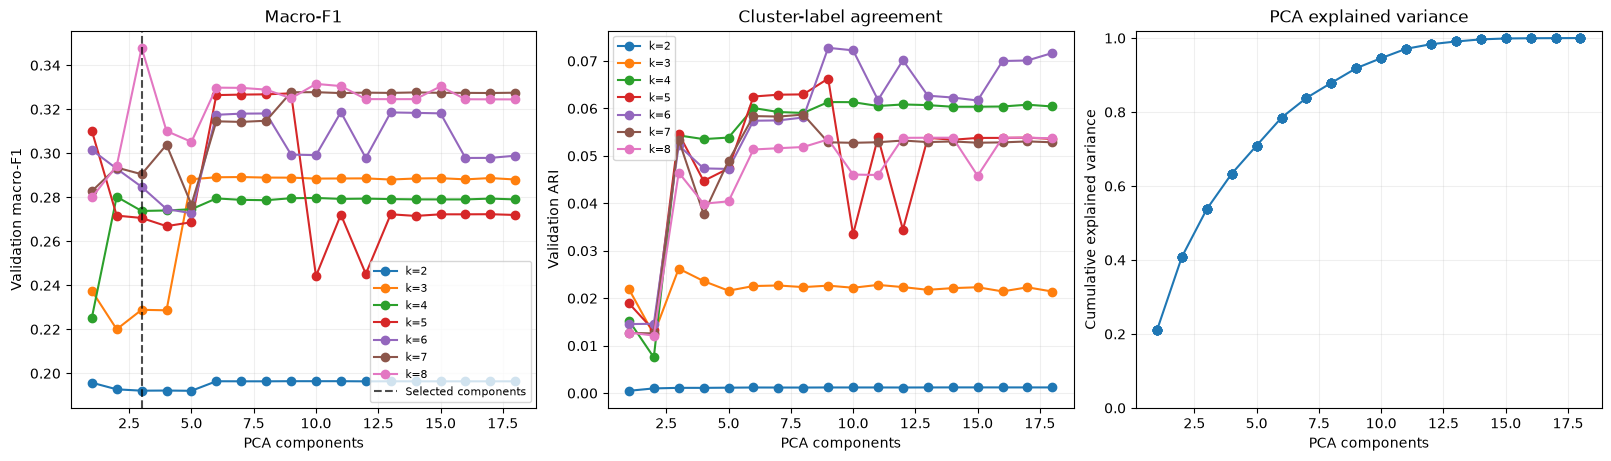

In [54]:
"""
with both:
"""

# --------------------------------------------------
# PCA component count + K-means cluster count search
# --------------------------------------------------


# --------------------------------------------------
# 1. Fit preprocessing BEFORE PCA on training data
# --------------------------------------------------

base_preprocess = Pipeline([
    ("scaler", StandardScaler()),
    ("variance", VarianceThreshold(threshold=0.0))
])

X_train_prepared = base_preprocess.fit_transform(
    train[extended_features]
)

X_val_prepared = base_preprocess.transform(
    val[extended_features]
)

y_train = train["degradation_status"].to_numpy()
y_val = val["degradation_status"].to_numpy()

class_names = ["Normal", "Moderate", "Severe", "Critical"]


# --------------------------------------------------
# 2. Define search spaces
# --------------------------------------------------

max_components = min(X_train_prepared.shape)

# You can reduce this if the full search is slow.
pca_component_candidates = range(1, max_components + 1)

# k does not need to equal the number of degradation classes.
kmeans_cluster_candidates = range(2, 9)

# Use sampling for silhouette if the dataset is large.
silhouette_sample_size = 10_000


# --------------------------------------------------
# 3. Helper: map clusters to degradation statuses
# --------------------------------------------------

def map_clusters_to_statuses(train_clusters, y_train):
    """
    Assign each cluster the most frequent training degradation status.
    """
    mapping_df = pd.DataFrame({
        "cluster": train_clusters,
        "degradation_status": y_train
    })

    mapping = (
        mapping_df
        .groupby("cluster")["degradation_status"]
        .agg(lambda s: s.mode().iloc[0])
        .to_dict()
    )

    return mapping


def predict_from_clusters(val_clusters, mapping):
    return np.array([
        mapping[cluster]
        for cluster in val_clusters
    ])


# --------------------------------------------------
# 4. Search PCA components and k-means k jointly
# --------------------------------------------------

results = []
best_model = None
best_macro_f1 = -np.inf

for n_components in pca_component_candidates:

    pca = PCA(
        n_components=n_components,
        svd_solver="full",
        whiten=False,
        random_state=42
    )

    X_train_pca = pca.fit_transform(X_train_prepared)
    X_val_pca = pca.transform(X_val_prepared)

    explained_variance = pca.explained_variance_ratio_.sum()

    for k in kmeans_cluster_candidates:

        kmeans = KMeans(
            n_clusters=k,
            n_init=10,
            random_state=42
        )

        train_clusters = kmeans.fit_predict(X_train_pca)
        val_clusters = kmeans.predict(X_val_pca)

        mapping = map_clusters_to_statuses(
            train_clusters,
            y_train
        )

        y_pred = predict_from_clusters(
            val_clusters,
            mapping
        )

        macro_f1 = f1_score(
            y_val,
            y_pred,
            labels=class_names,
            average="macro",
            zero_division=0
        )

        ari = adjusted_rand_score(
            y_val,
            val_clusters
        )

        nmi = normalized_mutual_info_score(
            y_val,
            val_clusters
        )

        accuracy = accuracy_score(
            y_val,
            y_pred
        )

        # Silhouette is only defined for 2 <= k <= n_samples - 1.
        sample_idx = np.random.RandomState(42).choice(
            X_train_pca.shape[0],
            size=min(
                silhouette_sample_size,
                X_train_pca.shape[0]
            ),
            replace=False
        )

        silhouette = silhouette_score(
            X_train_pca[sample_idx],
            train_clusters[sample_idx],
            sample_size=None,
            random_state=42
        )

        cluster_sizes = np.bincount(
            train_clusters,
            minlength=k
        )

        results.append({
            "n_components": n_components,
            "k": k,
            "explained_variance": explained_variance,
            "ari": ari,
            "nmi": nmi,
            "accuracy": accuracy,
            "macro_f1": macro_f1,
            "silhouette": silhouette,
            "min_cluster_size": cluster_sizes.min(),
            "max_cluster_size": cluster_sizes.max(),
            "n_predicted_classes": len(np.unique(y_pred)),
            "critical_predicted": int(
                np.sum(y_pred == "Critical")
            )
        })

        # Keep the best validation macro-F1.
        # Ties favour fewer PCA components, then smaller k.
        if macro_f1 > best_macro_f1:
            best_macro_f1 = macro_f1

            best_model = {
                "n_components": n_components,
                "k": k,
                "pca": pca,
                "kmeans": kmeans,
                "mapping": mapping
            }


# --------------------------------------------------
# 5. Show and inspect search results
# --------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    ["macro_f1", "ari", "n_components", "k"],
    ascending=[False, False, True, True]
).reset_index(drop=True)

print(results_df.to_string(index=False))

print("\nBest configuration by validation macro-F1:")
print(f"PCA components: {best_model['n_components']}")
print(f"K-means clusters: {best_model['k']}")
print(f"Validation macro-F1: {best_macro_f1:.4f}")
print("\nCluster-to-status mapping:")
print(best_model["mapping"])


# --------------------------------------------------
# 6. Show the top configurations
# --------------------------------------------------

print("\nTop 15 configurations:")
print(
    results_df
    .head(15)
    .to_string(index=False)
)


# --------------------------------------------------
# 7. Rebuild predictions for the selected model
# --------------------------------------------------

best_pca = best_model["pca"]
best_kmeans = best_model["kmeans"]
cluster_to_status = best_model["mapping"]

X_train_transformed = best_pca.transform(X_train_prepared)
X_val_transformed = best_pca.transform(X_val_prepared)

train_clusters = best_kmeans.predict(X_train_transformed)
val_clusters = best_kmeans.predict(X_val_transformed)

train_predictions = np.array([
    cluster_to_status[cluster]
    for cluster in train_clusters
])

val_predictions = np.array([
    cluster_to_status[cluster]
    for cluster in val_clusters
])


# --------------------------------------------------
# 8. Attach results to original DataFrames
# --------------------------------------------------

train_clusters_df = train.copy()
val_clusters_df = val.copy()

train_clusters_df["kmeans_cluster"] = train_clusters
val_clusters_df["kmeans_cluster"] = val_clusters

train_clusters_df["predicted_degradation_status"] = train_predictions
val_clusters_df["predicted_degradation_status"] = val_predictions


# --------------------------------------------------
# 9. Detailed validation performance
# --------------------------------------------------

print("\nValidation classification report:")
print(classification_report(
    y_val,
    val_predictions,
    labels=class_names,
    zero_division=0
))

confusion_df = pd.DataFrame(
    confusion_matrix(
        y_val,
        val_predictions,
        labels=class_names
    ),
    index=[f"Actual {label}" for label in class_names],
    columns=[f"Predicted {label}" for label in class_names]
)

print("\nValidation confusion matrix:")
print(confusion_df)


# --------------------------------------------------
# 10. Inspect cluster composition and profiles
# --------------------------------------------------

print("\nTraining cluster-status distribution:")
print(
    pd.crosstab(
        train_clusters_df["kmeans_cluster"],
        train_clusters_df["degradation_status"],
        normalize="index"
    ).round(3)
)

print("\nValidation cluster-status distribution:")
print(
    pd.crosstab(
        val_clusters_df["kmeans_cluster"],
        val_clusters_df["degradation_status"],
        normalize="index"
    ).round(3)
)

profile_features = [
    "depth_of_discharge_pct",
    "charge_c_rate",
    "discharge_c_rate",
    #"pack_temp_c",
    "high_soc_exposure_fraction",
    "energy_discharged_kwh",
    "battery_age_days",
    "equivalent_full_cycles"
]

print("\nCluster profiles:")
print(
    train_clusters_df
    .groupby("kmeans_cluster")[profile_features]
    .mean()
    .round(3)
)


# --------------------------------------------------
# 11. Visualise performance across k and PCA components
# --------------------------------------------------

plot_results = results_df.sort_values(
    ["n_components", "k"]
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.5),
    layout="constrained"
)

for k in sorted(plot_results["k"].unique()):
    subset = plot_results[
        plot_results["k"] == k
    ]

    axes[0].plot(
        subset["n_components"],
        subset["macro_f1"],
        marker="o",
        label=f"k={k}"
    )

axes[0].axvline(
    best_model["n_components"],
    color="black",
    linestyle="--",
    alpha=0.7,
    label="Selected components"
)

axes[0].set_xlabel("PCA components")
axes[0].set_ylabel("Validation macro-F1")
axes[0].set_title("Macro-F1")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.2)

for k in sorted(plot_results["k"].unique()):
    subset = plot_results[
        plot_results["k"] == k
    ]

    axes[1].plot(
        subset["n_components"],
        subset["ari"],
        marker="o",
        label=f"k={k}"
    )

axes[1].set_xlabel("PCA components")
axes[1].set_ylabel("Validation ARI")
axes[1].set_title("Cluster-label agreement")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.2)

axes[2].plot(
    plot_results["n_components"],
    plot_results["explained_variance"],
    marker="o"
)

axes[2].set_xlabel("PCA components")
axes[2].set_ylabel("Cumulative explained variance")
axes[2].set_title("PCA explained variance")
axes[2].set_ylim(0, 1.02)
axes[2].grid(alpha=0.2)

plt.show()